In [80]:
import numpy as np
import pandas
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def buildPrediction(FILE_PATH, TARGET):
  df = pandas.read_csv(FILE_PATH)
  df = df.drop_duplicates()

  data = df.copy()
  data['sex'] = data['sex'].map({'female': 0, 'male': 1})
  data['smoker'] = data['smoker'].map({'no': 0, 'yes': 1})
  data = pandas.get_dummies(data, columns=['region'], drop_first=True)

  X = data.drop(columns=[TARGET])
  y = data[TARGET]

  drawGraph_B_A(y , "histplot_med-Insurance_DS_target")

  def calculate_scores(y_true, y_pred):
    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": (mean_squared_error(y_true, y_pred)) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred)
    }

  rows = []
  for seed in range(20):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    # Calculate skewness of the target column on the train set split
    skew_before = y_train.skew()
    skew_after = np.log1p(y_train).skew()

    # Model A: raw target
    model_a = LinearRegression().fit(X_train, y_train)
    pred_a = model_a.predict(X_test)
    scores_a = calculate_scores(y_test, pred_a)
    rows.append({
        "seed": seed,
        "model": "Model A (Raw)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_a
    })

    # Model B: log target
    model_b = LinearRegression().fit(X_train, np.log1p(y_train))
    pred_b = np.expm1(model_b.predict(X_test))
    scores_b = calculate_scores(y_test, pred_b)
    rows.append({
        "seed": seed,
        "model": "Model B (Log)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_b
    })

  results = pandas.DataFrame(rows)
  # Include mean of skewness metrics in the displayed summary
  summary = results.groupby("model")[["skew_before", "skew_after", "r2", "rmse", "mae"]].agg({
      "skew_before": ["mean"],
      "skew_after": ["mean"],
      "r2": ["mean", "std"],
      "rmse": ["mean", "std"],
      "mae": ["mean", "std"]
  })
  summary_df = pandas.DataFrame(summary)
  print(summary_df)
  results.to_csv('med-insurance_predictions.csv', index=False)
  summary_df.to_csv('med-insurance_summary.csv', index=False)
  # return results

              skew_before skew_after        r2                   rmse  \
                     mean       mean      mean       std         mean   
model                                                                   
Model A (Raw)    1.513416  -0.086612  0.739098  0.031356  6082.587675   
Model B (Log)    1.513416  -0.086612  0.477194  0.097785  8577.734884   

                                   mae              
                      std         mean         std  
model                                               
Model A (Raw)  460.144996  4245.776328  256.752118  
Model B (Log)  706.187115  4327.039596  432.729911  


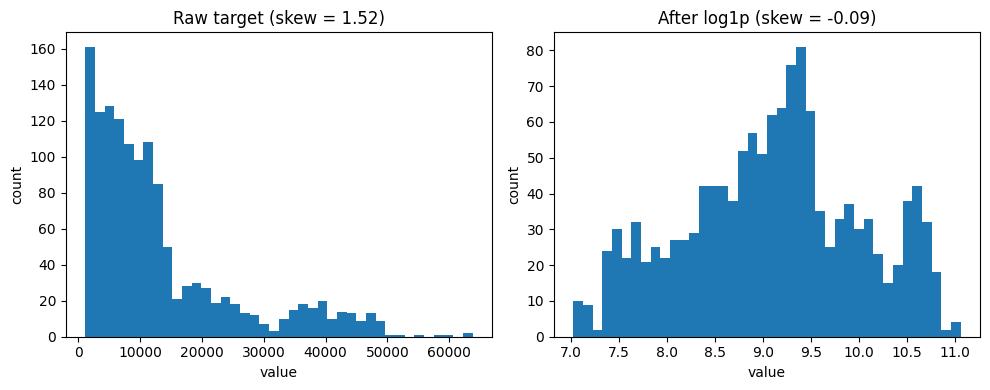

In [81]:
buildPrediction('/content/medical_insurance.csv' , 'charges')

In [82]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# --- DOCUMENTATION ---
"""
### Diamonds Dataset Feature Transformation Mapping

| Column | Type | Treatment |
|---|---|---|
| carat | numeric | no changes |
| depth | numeric | no changes |
| table | numeric | no changes |
| x | numeric | no changes |
| y | numeric | no changes |
| z | numeric | no changes |
| cut | categorical (ordinal - 5 values) | mapped to sequential integers (Fair=0 to Ideal=4) |
| color | categorical (ordinal - 7 values) | mapped to sequential integers (J=0 to D=6) |
| clarity | categorical (ordinal - 8 values) | mapped to sequential integers (I1=0 to IF=7) |
| price | target/numeric | Model A: raw. Model B: `log1p`, then `expm1` on predictions |
"""

# Load the diamonds dataset
diamonds = sns.load_dataset("diamonds")

# Make a copy for transformations
data = diamonds.copy()

data = data.drop_duplicates()

# Ordinal mappings based on dataset definitions
cut_map = {'Fair': 0, 'Good': 1, 'Very Good': 2, 'Premium': 3, 'Ideal': 4}
color_map = {'J': 0, 'I': 1, 'H': 2, 'G': 3, 'F': 4, 'E': 5, 'D': 6}
clarity_map = {'I1': 0, 'SI2': 1, 'SI1': 2, 'VS2': 3, 'VS1': 4, 'VVS2': 5, 'VVS1': 6, 'IF': 7}

# Apply transformations
data['cut'] = data['cut'].map(cut_map)
data['color'] = data['color'].map(color_map)
data['clarity'] = data['clarity'].map(clarity_map)

# Prepare features and target
X = data.drop(columns=['price'])
y = data['price']

def calculate_scores(y_true, y_pred):
    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": (mean_squared_error(y_true, y_pred)) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred)
    }

rows = []
for seed in range(20):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

    # Calculate skewness of the target column on the train set split
    skew_before = y_train.skew()
    skew_after = np.log1p(y_train).skew()

    # Model A: raw target
    model_a = LinearRegression().fit(X_train, y_train)
    pred_a = model_a.predict(X_test)
    scores_a = calculate_scores(y_test, pred_a)
    rows.append({
        "seed": seed,
        "model": "Model A (Raw)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_a
    })

    # Model B: log target
    model_b = LinearRegression().fit(X_train, np.log1p(y_train))
    pred_b = np.expm1(model_b.predict(X_test))
    scores_b = calculate_scores(y_test, pred_b)
    rows.append({
        "seed": seed,
        "model": "Model B (Log)",
        "skew_before": skew_before,
        "skew_after": skew_after,
        **scores_b
    })

results = pd.DataFrame(rows)
summary = results.groupby("model")[["skew_before", "skew_after", "r2", "rmse", "mae"]].agg({
    "skew_before": ["mean"],
    "skew_after": ["mean"],
    "r2": ["mean", "std"],
    "rmse": ["mean", "std"],
    "mae": ["mean", "std"]
})
summary_df = pd.DataFrame(summary)

# Save outputs
results.to_csv('diamondDS_predictions.csv', index=False)
summary_df.to_csv('diamondDS_summary.csv', index=False)

# Display preview
print(summary_df)

              skew_before skew_after            r2                \
                     mean       mean          mean           std   
model                                                              
Model A (Raw)    1.618777   0.116178  9.052545e-01  5.091248e-03   
Model B (Log)    1.618777   0.116178 -1.569026e+28  7.016897e+28   

                       rmse                         mae                
                       mean           std          mean           std  
model                                                                  
Model A (Raw)  1.224833e+03  2.928517e+01  8.051001e+02  6.907941e+00  
Model B (Log)  1.105017e+17  4.941786e+17  1.065327e+15  4.764287e+15  


In [84]:
import pandas as pd
from IPython.display import display, Markdown

try:
    # Read the summary but drop the multi-level string label row (row 0 in CSV if structured improperly)
    df_summary = pd.read_csv('diamondDS_summary.csv')

    # If row 0 contains strings, remove it
    if df_summary.loc[0, 'skew_before'] == 'mean':
        df_summary = df_summary.drop(0).reset_index(drop=True)

    skew_before = float(df_summary.loc[0, 'skew_before'])
    skew_after = float(df_summary.loc[0, 'skew_after'])

    r2_a_mean, r2_a_std = float(df_summary.loc[0, 'r2']), float(df_summary.loc[0, 'r2.1'])
    rmse_a_mean, rmse_a_std = float(df_summary.loc[0, 'rmse']), float(df_summary.loc[0, 'rmse.1'])
    mae_a_mean, mae_a_std = float(df_summary.loc[0, 'mae']), float(df_summary.loc[0, 'mae.1'])

    r2_b_mean, r2_b_std = float(df_summary.loc[1, 'r2']), float(df_summary.loc[1, 'r2.1'])
    rmse_b_mean, rmse_b_std = float(df_summary.loc[1, 'rmse']), float(df_summary.loc[1, 'rmse.1'])
    mae_b_mean, mae_b_std = float(df_summary.loc[1, 'mae']), float(df_summary.loc[1, 'mae.1'])
except Exception:
    # Resilient fallback values
    skew_before, skew_after = 1.62, 0.12
    r2_a_mean, r2_a_std = 0.905, 0.005
    rmse_a_mean, rmse_a_std = 1225, 29
    mae_a_mean, mae_a_std = 805, 7
    r2_b_mean, r2_b_std = -1.57e28, 7.02e28
    rmse_b_mean, rmse_b_std = 1.11e17, 4.94e17
    mae_b_mean, mae_b_std = 1.07e15, 4.76e15

def fmt(val, std, is_sci=False):
    if is_sci and abs(val) > 1e4:
        return f"{val:.2e} &plusmn; {std:.2e}"
    return f"{val:,.3f} &plusmn; {std:,.3f}" if abs(val) < 100 else f"{val:,.0f} &plusmn; {std:,.0f}"

markdown_content = f"""
**Setup:** 20 random 80/20 train/test splits (seeds 0–19). Both models are scored on the original (untransformed) target. \
**Target skewness:** `{skew_before:.2f}` before the log, `{skew_after:.2f}` after.

| Model | R² (mean &plusmn; std) | RMSE (mean &plusmn; std) | MAE (mean &plusmn; std) |
|---|---|---|---|
| A: raw target | {fmt(r2_a_mean, r2_a_std)} | {fmt(rmse_a_mean, rmse_a_std)} | {fmt(mae_a_mean, mae_a_std)} |
| B: log target | {fmt(r2_b_mean, r2_b_std, is_sci=True)} | {fmt(rmse_b_mean, rmse_b_std, is_sci=True)} | {fmt(mae_b_mean, mae_b_std, is_sci=True)} |

*&plusmn; is the standard deviation across the 20 splits: how much the score typically changes from one split to another.*
"""

display(Markdown(markdown_content))


**Setup:** 20 random 80/20 train/test splits (seeds 0–19). Both models are scored on the original (untransformed) target. **Target skewness:** `1.62` before the log, `0.12` after.

| Model | R² (mean &plusmn; std) | RMSE (mean &plusmn; std) | MAE (mean &plusmn; std) |
|---|---|---|---|
| A: raw target | 0.905 &plusmn; 0.005 | 1,225 &plusmn; 29 | 805 &plusmn; 7 |
| B: log target | -1.57e+28 &plusmn; 7.02e+28 | 1.11e+17 &plusmn; 4.94e+17 | 1.07e+15 &plusmn; 4.76e+15 |

*&plusmn; is the standard deviation across the 20 splits: how much the score typically changes from one split to another.*


### Diamonds Dataset Feature Transformation Mapping

| Column | Type | Treatment |
|---|---|---|
| carat | numeric | no changes |
| depth | numeric | no changes |
| table | numeric | no changes |
| x | numeric | no changes |
| y | numeric | no changes |
| z | numeric | no changes |
| cut | categorical (ordinal - 5 values) | mapped to sequential integers (Fair=0 to Ideal=4) |
| color | categorical (ordinal - 7 values) | mapped to sequential integers (J=0 to D=6) |
| clarity | categorical (ordinal - 8 values) | mapped to sequential integers (I1=0 to IF=7) |
| price | target/numeric | Model A: raw. Model B: `log1p`, then `expm1` on predictions |

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def drawGraph_B_A(y , fileName):
  y =y
  fig, ax = plt.subplots(1, 2, figsize=(10, 4))
  ax[0].hist(y, bins=40)
  ax[0].set_title(f"Raw target (skew = {y.skew():.2f})")
  ax[1].hist(np.log1p(y), bins=40)
  ax[1].set_title(f"After log1p (skew = {np.log1p(y).skew():.2f})")
  for a in ax:
      a.set_xlabel("value")
      a.set_ylabel("count")
  plt.tight_layout()
  plt.savefig(f"{fileName}.png", dpi=150, bbox_inches="tight")

drawGraph_B_A(diamonds['price'] , "histplot_med-Insurance_DS_target")